<a href="https://colab.research.google.com/github/Joseph-Ndiva/python-assignment/blob/main/week4%20assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from datasets import load_dataset


In [2]:
data = load_dataset("electricsheepafrica/nigerian_transport_and_logistics_ride_hailing")

README.md:   0%|          | 0.00/6.07k [00:00<?, ?B/s]

nigerian_transport_and_logistics_ride_ha(…): reconstructing file:   0%|          |  0.00B / 15.0MB            

nigerian_transport_and_logistics_ride_ha(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/220000 [00:00<?, ? examples/s]

In [3]:
data

DatasetDict({
    train: Dataset({
        features: ['trip_id', 'pickup_time', 'dropoff_time', 'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon', 'distance_km', 'duration_min', 'surge_mult', 'fare_ngn'],
        num_rows: 220000
    })
})

In [4]:
data_tr = load_dataset("electricsheepafrica/nigerian_transport_and_logistics_ride_hailing", split="train")
data_tr_sample = load_dataset("electricsheepafrica/nigerian_transport_and_logistics_ride_hailing", split="train[:1000]")
print(data_tr)
print()
print(data_tr_sample)

Dataset({
    features: ['trip_id', 'pickup_time', 'dropoff_time', 'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon', 'distance_km', 'duration_min', 'surge_mult', 'fare_ngn'],
    num_rows: 220000
})

Dataset({
    features: ['trip_id', 'pickup_time', 'dropoff_time', 'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon', 'distance_km', 'duration_min', 'surge_mult', 'fare_ngn'],
    num_rows: 1000
})


In [5]:
data_tr[0]

{'trip_id': 'RH-000000000',
 'pickup_time': '2025-02-27 22:14:44',
 'dropoff_time': '2025-02-27 22:44:44',
 'pickup_lat': 11.999537,
 'pickup_lon': 8.54536,
 'dropoff_lat': 8.919016,
 'dropoff_lon': 7.282634,
 'distance_km': 2.66,
 'duration_min': 30.0,
 'surge_mult': 1.02,
 'fare_ngn': 1497.0}

In [6]:
data_tr_sample["distance_km"][:10]

[2.66, 7.51, 5.87, 4.23, 7.49, 9.63, 3.72, 5.31, 38.02, 6.52]

In [7]:
data_tr["distance_km"][:10]

[2.66, 7.51, 5.87, 4.23, 7.49, 9.63, 3.72, 5.31, 38.02, 6.52]

In [8]:
data_tr["fare_ngn"][:10]

[1497.0, 1230.0, 1123.0, 837.0, 2151.0, 2980.0, 1463.0, 1248.0, 7571.0, 1408.0]

In [10]:
import pandas as pd
import numpy as np

# Convert the sample dataset to a pandas DataFrame
df = data_tr.to_pandas()

# Select the distance column and remove missing values
distance = df["distance_km"].dropna()

# Calculate descriptive statistics
mean = distance.mean()
median = distance.median()
data_range = distance.max() - distance.min()
variance = distance.var()
std_deviation = distance.std()

# Display the results
print("Mean:", mean)
print("Median:", median)
print("Range:", data_range)
print("Variance:", variance)
print("Standard Deviation:", std_deviation)

Mean: 11.547802499999994
Median: 9.04
Range: 119.5
Variance: 83.78176471129736
Standard Deviation: 9.153237935905379


In [12]:
df = data_tr.to_pandas()
fare = df["fare_ngn"].dropna()
# Calculate descriptive statistics
mean = fare.mean()
median = fare.median()
data_range = fare.max() - fare.min()
variance = fare.var()
std_deviation = fare.std()

# Display the results
print("Mean:", mean)
print("Median:", median)
print("Range:", data_range)
print("Variance:", variance)
print("Standard Deviation:", std_deviation)

Mean: 2328.960727272727
Median: 2001.0
Range: 22062.0
Variance: 1763333.2810362347
Standard Deviation: 1327.9055994445669


In [13]:
# Convert the Hugging Face dataset to a DataFrame
df = data_tr_sample.to_pandas()

# Select distance and fare, removing rows with missing values
data = df[["distance_km", "fare_ngn"]].dropna()

# Calculate covariance
covariance = data["distance_km"].cov(data["fare_ngn"])

# Calculate correlation
correlation = data["distance_km"].corr(data["fare_ngn"])

# Display results
print("Covariance:", covariance)
print("Correlation:", correlation)

Covariance: 7912.838065025024
Correlation: 0.8106579189076425


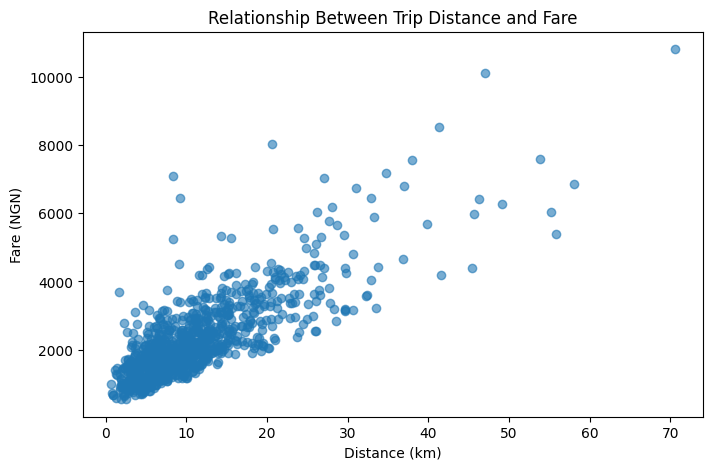

In [14]:
import matplotlib.pyplot as plt

# Convert the Hugging Face dataset to a pandas DataFrame
df = data_tr_sample.to_pandas()

# Remove rows with missing values
data = df[["distance_km", "fare_ngn"]].dropna()

# Create scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(data["distance_km"], data["fare_ngn"], alpha=0.6)

# Add labels and title
plt.title("Relationship Between Trip Distance and Fare")
plt.xlabel("Distance (km)")
plt.ylabel("Fare (NGN)")

# Display the plot
plt.show()

The graph show cleary the relationship between the distance and fare where the the more distance covered th more fare, the relationship is almost linear. Also the majority of trips by the app is between 0-20 km with very few trips outside that range.However there are outliers within the range where fare was high. This can be attributed to various factors. There is strong correlation betweeen the distance covered and fare at more than 80%.


Fare = distance*rate/km + minimum_fare